Dataset shape: (50, 6)

First 5 rows:


,Sample,Oil,Density,Crispy,Fracture,Hardness
0,B110,16.5,2955,10,23,97
1,B136,17.7,2660,14,9,139
2,B171,16.2,2870,12,17,143
3,B192,16.7,2920,10,31,95
4,B225,16.3,2975,11,26,143



Numeric features: ['Oil', 'Density', 'Crispy', 'Fracture', 'Hardness']

Summary statistics:


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,missing,iqr
Oil,50.0,17.202,1.592007,13.7,16.30,16.9,18.10,21.2,0.440699,0.609722,0,1.8
Density,50.0,2857.600,124.499980,2570.0,2772.50,2867.5,2945.00,3125.0,-0.191231,-0.265236,0,172.5
Crispy,50.0,11.520,1.775571,7.0,10.00,12.0,13.00,15.0,-0.296292,-0.287087,0,3.0
Fracture,50.0,20.860,5.466073,9.0,17.00,21.0,25.00,33.0,-0.114545,-0.438414,0,8.0
Hardness,50.0,128.180,31.127578,63.0,107.25,126.0,143.75,192.0,0.007044,-0.218104,0,36.5


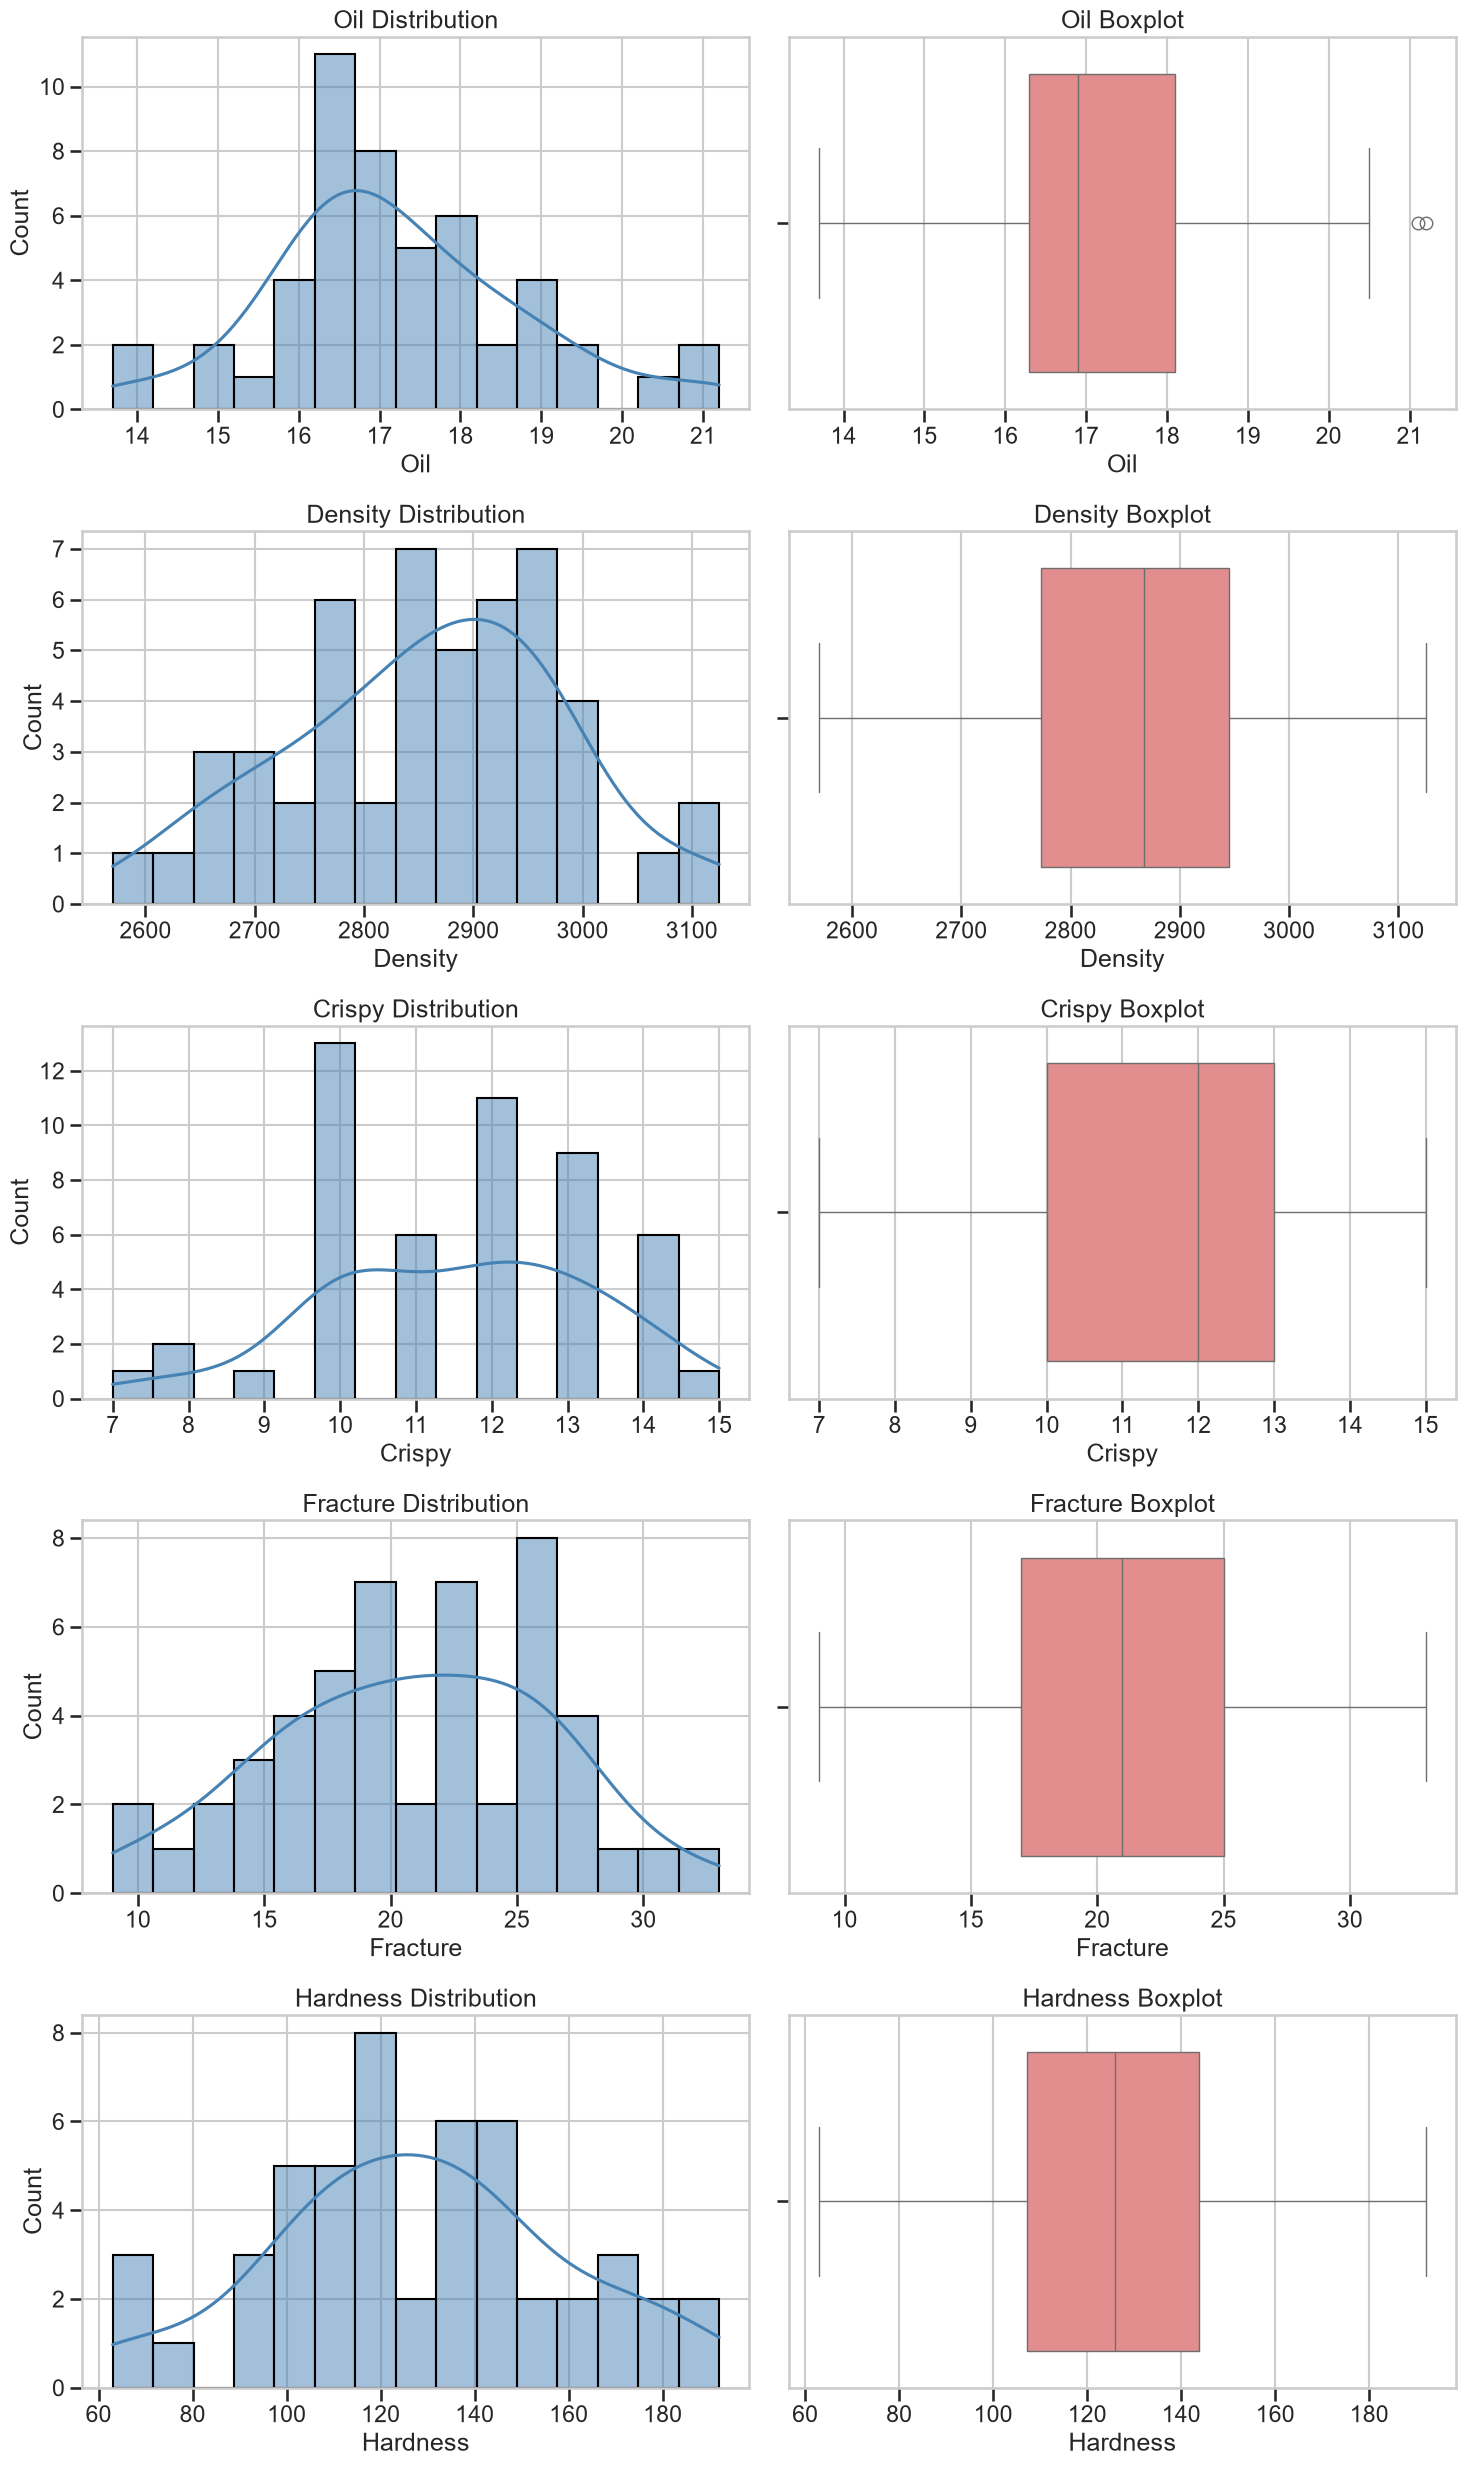

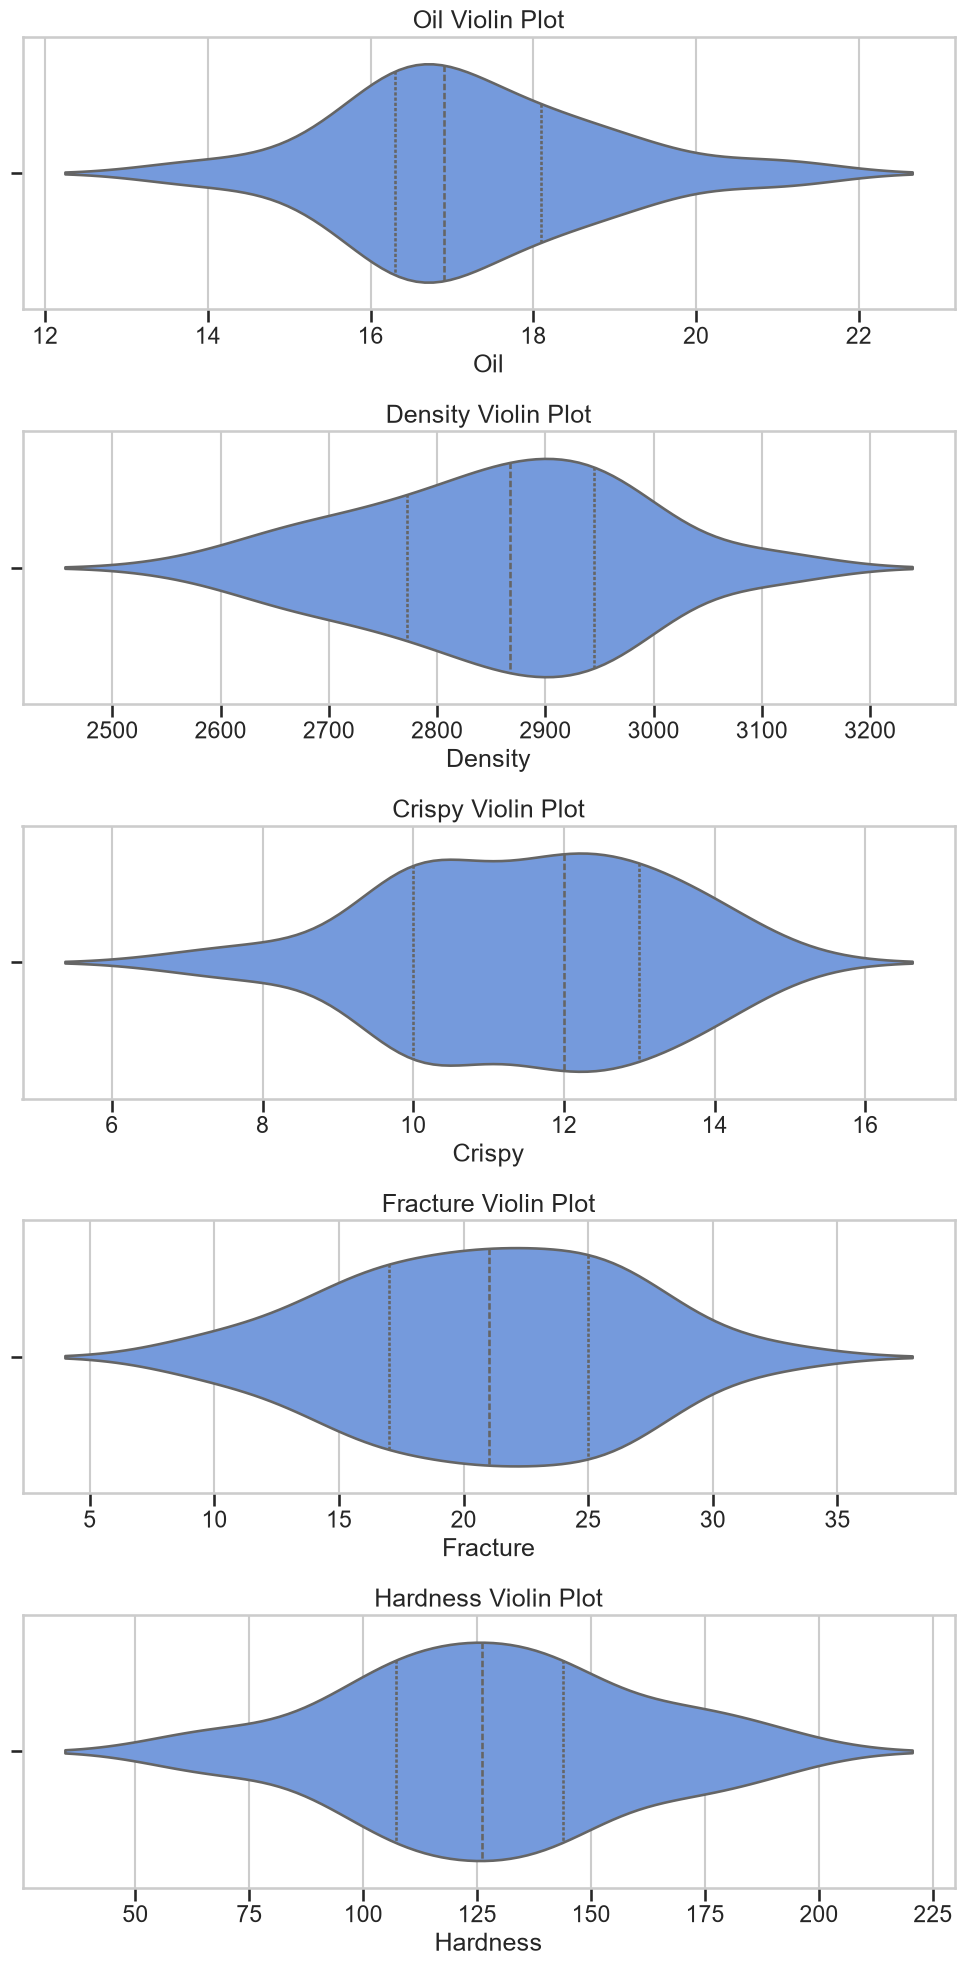

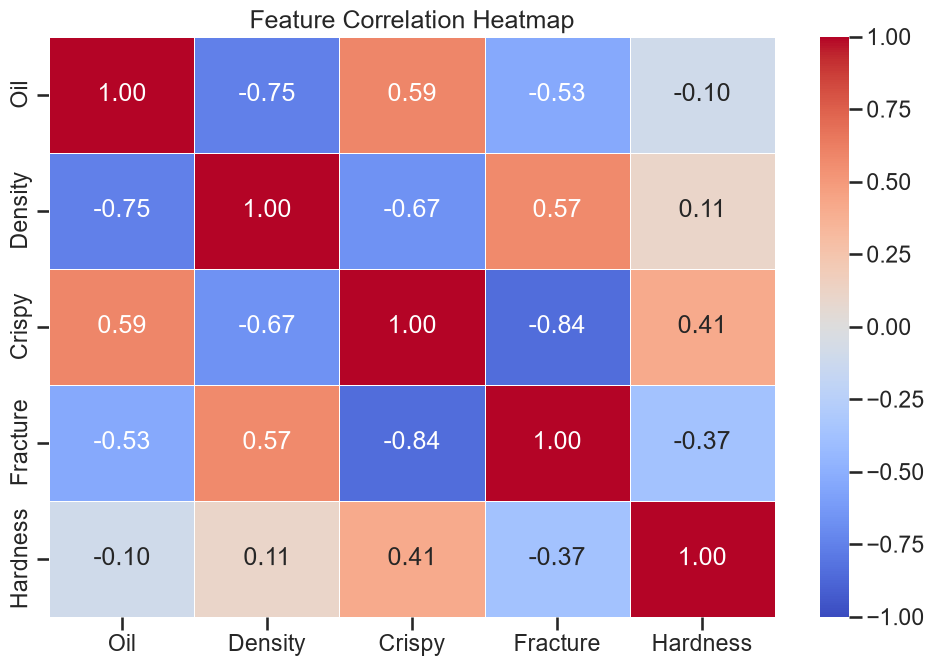

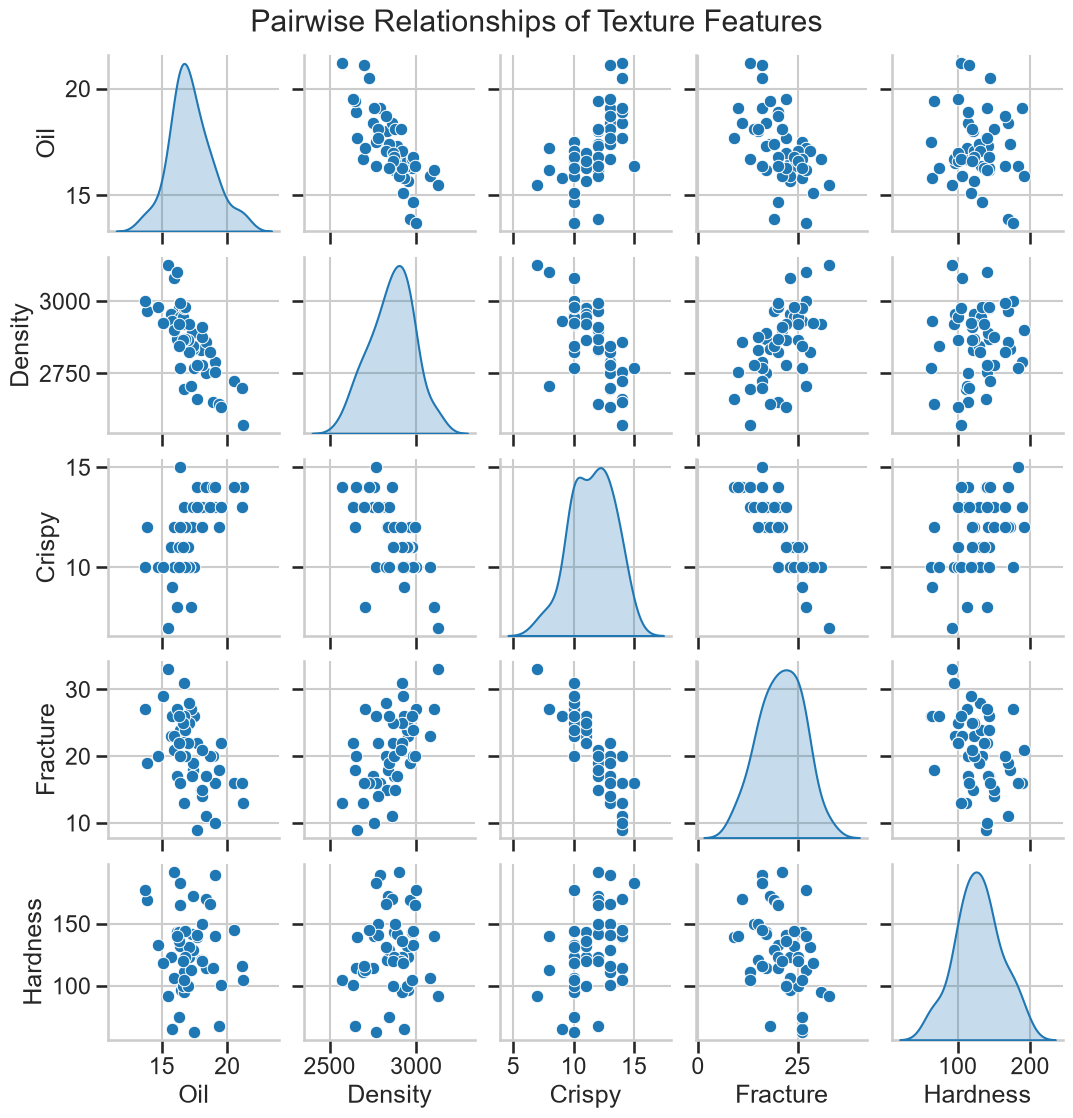


Normality test (Shapiro-Wilk):
Oil: statistic=0.9681, p-value=0.1927
Density: statistic=0.9828, p-value=0.6765
Crispy: statistic=0.9489, p-value=0.0308
Fracture: statistic=0.9873, p-value=0.8632
Hardness: statistic=0.9808, p-value=0.5878

Outlier check using IQR rule:
Oil: Q1=16.30, Q3=18.10, IQR=1.80, Lower=13.60, Upper=20.80, Outliers=2
Density: Q1=2772.50, Q3=2945.00, IQR=172.50, Lower=2513.75, Upper=3203.75, Outliers=0
Crispy: Q1=10.00, Q3=13.00, IQR=3.00, Lower=5.50, Upper=17.50, Outliers=0
Fracture: Q1=17.00, Q3=25.00, IQR=8.00, Lower=5.00, Upper=37.00, Outliers=0
Hardness: Q1=107.25, Q3=143.75, IQR=36.50, Lower=52.50, Upper=198.50, Outliers=0

Interpretation summary:
- Check skewness and kurtosis to identify non-normal distributions.
- Use the correlation heatmap to identify pairs of related texture features.
- Boxplots and violin plots reveal spread, center, and outlier behavior.
- Shapiro-Wilk results test whether each feature is approximately normal.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('talk')

# Load data
path = Path('food-texture.csv')
df = pd.read_csv(path)

# Clean the first column if it is just an unnamed index
if 'Unnamed: 0' in df.columns:
    df = df.rename(columns={'Unnamed: 0': 'Sample'})

# Keep only numeric features for EDA
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print('Dataset shape:', df.shape)
print('\nFirst 5 rows:')
display(df.head())
print('\nNumeric features:', numeric_cols)

# Descriptive statistics
summary = df[numeric_cols].describe().T
summary['skew'] = df[numeric_cols].skew()
summary['kurtosis'] = df[numeric_cols].kurtosis()
summary['missing'] = df[numeric_cols].isna().sum()
summary['iqr'] = df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25)
print('\nSummary statistics:')
display(summary)

# Feature distribution plots
fig, axes = plt.subplots(len(numeric_cols), 2, figsize=(15, 5 * len(numeric_cols)))
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=15, kde=True, ax=axes[i, 0], color='steelblue')
    axes[i, 0].set_title(f'{col} Distribution')
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel('Count')

    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'{col} Boxplot')
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

# Violin plots
fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(10, 4 * len(numeric_cols)))
for i, col in enumerate(numeric_cols):
    sns.violinplot(data=df, x=col, ax=axes[i], inner='quartile', color='cornflowerblue')
    axes[i].set_title(f'{col} Violin Plot')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

# Correlation heatmap
corr = df[numeric_cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

# Pairwise relationships
sns.pairplot(df[numeric_cols], diag_kind='kde', height=2.2)
plt.suptitle('Pairwise Relationships of Texture Features', y=1.02)
plt.show()

# Statistical tests and outlier checks
print('\nNormality test (Shapiro-Wilk):')
for col in numeric_cols:
    stat, p = stats.shapiro(df[col])
    print(f'{col}: statistic={stat:.4f}, p-value={p:.4f}')

print('\nOutlier check using IQR rule:')
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f'{col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, Lower={lower:.2f}, Upper={upper:.2f}, Outliers={len(outliers)}')

# Interpretive notes
print('\nInterpretation summary:')
print('- Check skewness and kurtosis to identify non-normal distributions.')
print('- Use the correlation heatmap to identify pairs of related texture features.')
print('- Boxplots and violin plots reveal spread, center, and outlier behavior.')
print('- Shapiro-Wilk results test whether each feature is approximately normal.')


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from 